<a href="https://colab.research.google.com/github/Gabrielrossimoras/praticas-extensionistas-iv/blob/main/Sprint5_Modelagem_Preditiva.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Esse código vai carregar o dataset que produzimos na Sprint 4.

In [1]:

import os
import pandas as pd

repositorio = "/content/praticas-extensionistas-iv"

if not os.path.isdir(repositorio):
    !git clone https://github.com/Gabrielrossimoras/praticas-extensionistas-iv.git

caminho = (
    "/content/praticas-extensionistas-iv/"
    "dados/tratados/dataset_final_treinamento.csv"
)

df = pd.read_csv(caminho)

print("Total de registros:", len(df))
print("Colunas disponíveis:")
print(df.columns.tolist())

display(df.head(10))


Cloning into 'praticas-extensionistas-iv'...
remote: Enumerating objects: 121, done.
remote: Counting objects: 100% (121/121), done.
remote: Compressing objects: 100% (114/114), done.
remote: Total 121 (delta 45), reused 2 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (121/121), 651.45 KiB | 8.25 MiB/s, done.
Resolving deltas: 100% (45/45), done.
Total de registros: 7
Colunas disponíveis:
['id_processo', 'data_abertura', 'tipo_servico', 'origem_atendimento', 'tipo_veiculo', 'status', 'data_conclusao', 'prazo_previsto', 'documentacao_pendente', 'valor_servico', 'dias_conclusao', 'prazo_dias', 'mes_abertura', 'dia_semana_abertura', 'concluido', 'atrasou']


,id_processo,data_abertura,tipo_servico,origem_atendimento,tipo_veiculo,status,data_conclusao,prazo_previsto,documentacao_pendente,valor_servico,dias_conclusao,prazo_dias,mes_abertura,dia_semana_abertura,concluido,atrasou
0,1,2026-09-28,licenciamento,cliente,automovel,concluido,2026-09-28,2026-10-01,nao,70,0.0,3,9,0,1,0.0
1,2,2026-09-29,transferencia,cliente,automovel,concluido,2026-09-30,2026-10-02,nao,150,1.0,3,9,1,1,0.0
2,3,2026-09-30,transferencia,cliente,automovel,concluido,2026-09-30,2026-10-03,nao,150,0.0,3,9,2,1,0.0
3,4,2026-10-01,licenciamento,cliente,motocicleta,concluido,2026-10-01,2026-10-04,nao,70,0.0,3,10,3,1,0.0
4,5,2026-10-02,licenciamento,cliente,automovel,concluido,2026-10-05,2026-10-05,nao,70,3.0,3,10,4,1,0.0
5,6,2026-10-05,transferencia,cliente,motocicleta,pendente,NaN,2026-10-08,vistoria,150,NaN,3,10,0,0,NaN
6,7,2026-10-06,licenciamento,cliente,caminhao,concluido,2026-10-06,2026-10-09,nao,70,0.0,3,10,1,1,0.0


In [2]:

# Separar somente processos concluídos
dados_modelo = df[
    (df["status"] == "concluido") &
    (df["dias_conclusao"].notna())
].copy()

# Selecionar informações conhecidas na abertura
atributos = [
    "tipo_servico",
    "tipo_veiculo",
    "origem_atendimento"
]

X = dados_modelo[atributos]
y = dados_modelo["dias_conclusao"]

print("Registros disponíveis para modelagem:", len(X))
print("\nVariáveis de entrada:")
display(X)

print("\nTempo real de conclusão (dias):")
display(y)


Registros disponíveis para modelagem: 6

Variáveis de entrada:


,tipo_servico,tipo_veiculo,origem_atendimento
0,licenciamento,automovel,cliente
1,transferencia,automovel,cliente
2,transferencia,automovel,cliente
3,licenciamento,motocicleta,cliente
4,licenciamento,automovel,cliente
6,licenciamento,caminhao,cliente



Tempo real de conclusão (dias):


,dias_conclusao
0,0.0
1,1.0
2,0.0
3,0.0
4,3.0
6,0.0


agora vamos:
1. Converter os tipos de serviço e veículo em informações numéricas.
2. Criar uma Árvore de Decisão com profundidade máxima de dois níveis.
3. Treinar o modelo utilizando os seis atendimentos concluídos.
4. Comparar os dias reais com os dias estimados pelo próprio modelo.

In [3]:

from sklearn.tree import DecisionTreeRegressor
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
import pandas as pd

# Preparar as variáveis categóricas
preprocessador = ColumnTransformer(
    transformers=[
        ("categorias", OneHotEncoder(handle_unknown="ignore"), atributos)
    ]
)

# Criar o modelo de regressão
modelo = Pipeline(steps=[
    ("preprocessamento", preprocessador),
    ("regressao", DecisionTreeRegressor(
        max_depth=2,
        random_state=42
    ))
])

# Treinar com os seis processos concluídos
modelo.fit(X, y)

# Verificar as estimativas nos próprios dados de treinamento
previsoes = modelo.predict(X)

resultado = pd.DataFrame({
    "Tipo de serviço": X["tipo_servico"],
    "Tipo de veículo": X["tipo_veiculo"],
    "Dias reais": y,
    "Dias estimados": previsoes.round(2)
})

print("Treinamento experimental concluído!")
display(resultado)


Treinamento experimental concluído!


,Tipo de serviço,Tipo de veículo,Dias reais,Dias estimados
0,licenciamento,automovel,0.0,1.5
1,transferencia,automovel,1.0,0.5
2,transferencia,automovel,0.0,0.5
3,licenciamento,motocicleta,0.0,0.0
4,licenciamento,automovel,3.0,1.5
6,licenciamento,caminhao,0.0,0.0


Agora vamos calcular duas métricas importantes:
- MAE: erro médio absoluto, indicando quantos dias o modelo errou, em média.
- RMSE: raiz do erro quadrático médio, que penaliza mais os erros maiores.

AVALIAÇÃO EXPERIMENTAL - SPRINT 5
MAE de treinamento: 0.67 dias
RMSE de treinamento: 0.91 dias


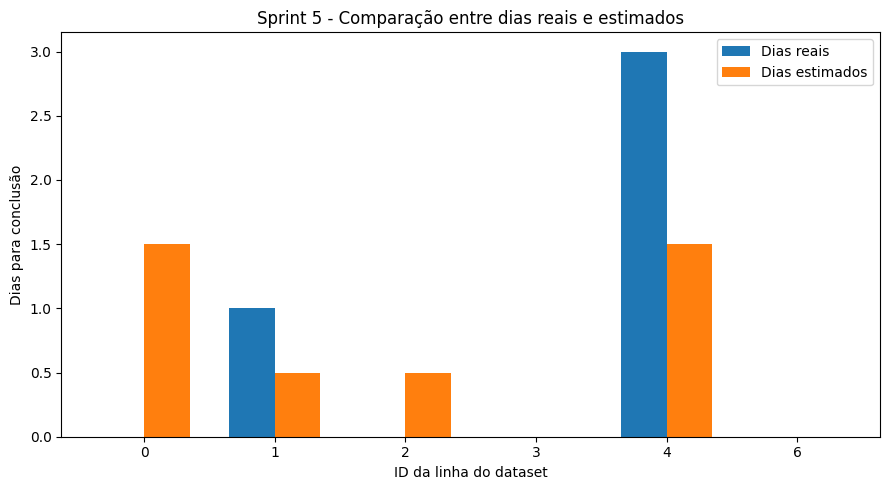

In [4]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import matplotlib.pyplot as plt

# Avaliação nos dados de treinamento
mae = mean_absolute_error(y, previsoes)
rmse = np.sqrt(mean_squared_error(y, previsoes))

print("AVALIAÇÃO EXPERIMENTAL - SPRINT 5")
print(f"MAE de treinamento: {mae:.2f} dias")
print(f"RMSE de treinamento: {rmse:.2f} dias")

# Comparar valores reais e estimados
plt.figure(figsize=(9, 5))

posicoes = np.arange(len(y))
largura = 0.35

plt.bar(posicoes - largura/2, y.to_numpy(),
        largura, label="Dias reais")

plt.bar(posicoes + largura/2, previsoes,
        largura, label="Dias estimados")

plt.xticks(posicoes, X.index.astype(str))
plt.xlabel("ID da linha do dataset")
plt.ylabel("Dias para conclusão")
plt.title("Sprint 5 - Comparação entre dias reais e estimados")
plt.legend()
plt.tight_layout()
plt.show()


Agora vamos testar como o sistema se comportaria ao receber um novo atendimento de transferência de automóvel.

In [5]:

import pandas as pd

# Novo atendimento fictício para demonstração
novo_atendimento = pd.DataFrame([{
    "tipo_servico": "transferencia",
    "tipo_veiculo": "automovel",
    "origem_atendimento": "cliente"
}])

# Gerar previsão experimental
previsao = modelo.predict(novo_atendimento)[0]

print("SPRINT 5 - SIMULAÇÃO DE NOVO ATENDIMENTO")
print("Serviço: Transferência")
print("Veículo: Automóvel")
print("Origem: Cliente")
print(f"Tempo estimado: {previsao:.2f} dia(s)")
print()
print("ATENÇÃO: previsão apenas demonstrativa.")
print("O modelo ainda não foi validado com dados independentes.")


SPRINT 5 - SIMULAÇÃO DE NOVO ATENDIMENTO
Serviço: Transferência
Veículo: Automóvel
Origem: Cliente
Tempo estimado: 0.50 dia(s)

ATENÇÃO: previsão apenas demonstrativa.
O modelo ainda não foi validado com dados independentes.


Simulação — Transferência de automóvel
0,50 dia
Estimativa demonstrativa, ainda sem validação independente.